# The embedding problem: does a generator exist, and which one to use

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 02 of this topic (the pooled matrix and the EM generator)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- say what the embedding problem asks (is a one-year matrix the exponential of a generator?) and why it matters to a PD at a horizon other than one year;
- run Israel, Rosenthal and Wei's checks on a real matrix and read each: the convergence of the log series, the three conditions that exclude an exact generator, stochastic monotonicity;
- compute the matrix logarithm by its series, find its negative off-diagonal entries and repair them with the diagonal, the weighted and the Jarrow-Lando-Turnbull adjustments, with every intermediate printed;
- compare the repairs and the EM generator by the L1 distance of the exponential to the matrix, and by the PD each gives at one and five years;
- compare the engine with the distances Israel et al. print, and say which of the nine does not reproduce and why.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.transitions import embedding
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed files of case C04:

- `data/derived/C04/sp.json`: the S&P pooled one-year matrix of notebook 02 (`outputs.pooled.matrix`, withdrawals removed, seven grades and default) and what the case computed from it: `outputs.embedding` (the diagnostics) and `outputs.generators` (the diagonal, weighted, JLT and EM generators with their L1 distances and PDs at one and five years). Source: ESMA CEREP (licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/).
- `data/derived/C04/published.json`: Israel, Rosenthal and Wei's printed L1 distances for three agency matrices, each with the value the engine recomputes. The paper's matrices are not committed (the artifact keeps only the distances), so this part of the notebook reads the comparison and cannot rerun it.

The next cell loads both and prints the engine version that baked them.

In [2]:
# Load the two artifacts (the notebook sits three folders below the repository root) and the pooled matrix
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))
published = json.loads((C04 / "published.json").read_text(encoding="utf-8"))
out = sp["outputs"]
states = out["states"]
P = np.array(out["pooled"]["matrix"], dtype=float)

for label, doc in (("sp", sp), ("published", published)):
    print(f"{label:10s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("pooled matrix:", P.shape, "| rows sum to one:", bool(np.allclose(P.sum(axis=1), 1.0)))
print("diagonal of P (grades, then default):", np.round(np.diag(P), 4))

sp         baked by riskvalidation 0.4.3 | installed 0.8.1
published  baked by riskvalidation 0.4.3 | installed 0.8.1
pooled matrix: (8, 8) | rows sum to one: True
diagonal of P (grades, then default): [0.8227 0.8901 0.9399 0.9294 0.8735 0.8692 0.7148 1.    ]


## Method

### Step 1: can this matrix have a generator?

A rating matrix $P$ is observed over one year, but a bank needs PDs at three or five years, and a continuous-time model needs a **generator** $Q$: non-negative off-diagonal entries (rates of moving), rows summing to zero, with $\exp(Q) = P$. The embedding problem asks whether such a $Q$ exists. Israel, Rosenthal and Wei (2001) give three tools, all in the engine's `embedding_diagnostics`:

- **Theorem 1.** With $S = \max\{(a-1)^2 + b^2 : a + bi \text{ an eigenvalue of } P\}$, if $S < 1$ the series $\tilde Q = (P - I) - \tfrac12 (P-I)^2 + \tfrac13 (P-I)^3 - \dots$ converges and $\exp(\tilde Q) = P$ exactly, with rows summing to zero. Theorem 2: if every $p_{ii} > 1/2$ then $S < 1$, and the generator, if any, is unique.
- **Theorem 3.** No exact generator exists if (a) $\det P \le 0$, (b) $\det P > \prod_i p_{ii}$, or (c) some state $j$ is reachable from $i$ while $p_{ij} = 0$.
- **Lemma 1** (Jarrow, Lando and Turnbull). The chain is stochastically monotone when $\sum_{j \ge k} p_{ij}$ does not decrease in $i$ for every $k$: a worse grade is never safer.

The next cell runs the diagnostics and names the states in the pairs of condition (c).

In [3]:
# Run the embedding diagnostics on the pooled matrix and compare them with the committed block
diag = embedding.embedding_diagnostics(P)
committed = out["embedding"]
print("S (Theorem 1):", round(diag["S"], 6), "| series converges:", diag["series_converges"], "| all diagonal entries above 1/2:", diag["all_diagonal_above_half"])
print("det P:", round(diag["det"], 6), "| product of p_ii:", round(diag["prod_diagonal"], 6))
print("Theorem 3 (a) det <= 0:", diag["theorem3_a"], "| (b) det > prod p_ii:", diag["theorem3_b"])
pairs = [f"{states[i]} to {states[j]}" for i, j in diag["theorem3_c"]]
print("Theorem 3 (c) reachable with p_ij = 0:", pairs)
print("an exact generator is excluded:", diag["exact_generator_excluded"])
print("stochastically monotone:", diag["stochastically_monotone"], "|", len(diag["monotonicity_violations"]), "violations")
for v in diag["monotonicity_violations"]:
    print(f"  column {states[v['column']]}: tail of {states[v['row']]} = {v['tail']:.6f}, tail of {states[v['next_row']]} = {v['next_tail']:.6f}")
print("baked by riskvalidation", sp["provenance"]["riskvalidation_version"], "| S, det and violations equal the committed block:",
      bool(np.isclose(diag["S"], committed["S"], atol=1e-8) and np.isclose(diag["det"], committed["det"], atol=1e-8) and len(diag["monotonicity_violations"]) == len(committed["monotonicity_violations"])))

S (Theorem 1): 0.120911 | series converges: True | all diagonal entries above 1/2: True
det P: 0.336394 | product of p_ii: 0.347143
Theorem 3 (a) det <= 0: False | (b) det > prod p_ii: False
Theorem 3 (c) reachable with p_ij = 0: ['AAA to BBB', 'AAA to BB', 'AAA to D', 'B to AAA', 'CCC-C to AAA', 'CCC-C to AA']
an exact generator is excluded: True
stochastically monotone: False | 4 violations
  column BB: tail of AAA = 0.003694, tail of AA = 0.000396
  column B: tail of AAA = 0.003694, tail of AA = 0.000248
  column CCC-C: tail of AAA = 0.001055, tail of AA = 0.000099
  column AA: tail of BBB = 0.999930, tail of BB = 0.999919
baked by riskvalidation 0.4.3 | S, det and violations equal the committed block: True


Read it: the series converges (S is well below 1), so the matrix has a candidate generator $\tilde Q$. But condition (c) of Theorem 3 holds in six pairs (AAA reaches BBB, BB and default in several steps, B reaches AAA, CCC-C reaches AAA and AA, while the pooled one-year matrix has zero for each), so **no exact generator exists**, and the chain also violates monotonicity in four cells. This is the usual situation with an empirical matrix. The question becomes which valid generator to use, and how far its exponential is from the matrix.

### Step 2: the matrix logarithm by its series

The engine's `log_series` sums Theorem 1's series until a term is below $10^{-14}$. Two independent checks apply. SciPy's `logm` gives the principal matrix logarithm by another algorithm, and the engine reports its distance to it. And the exponential of the result must give $P$ back. The result $\tilde Q$ is the unique candidate, and it is a generator only if no off-diagonal entry is negative. The cell prints how many are, the most negative ones and the row sums.

In [4]:
# Sum the log series, check it against SciPy's logm and by exponentiating, and list the negative off-diagonal entries
series = embedding.log_series(P)
q_tilde = series["generator"]
print("terms summed:", series["terms"], "| converged:", series["converged"])
print("distance to SciPy logm:", f"{series['distance_to_logm']:.2e}")
print("largest entry of exp(Q~) - P:", f"{np.abs(expm(q_tilde) - P).max():.2e}")
print("row sums of Q~ (zero):", f"{np.abs(q_tilde.sum(axis=1)).max():.2e}")

off = ~np.eye(len(states), dtype=bool)
negatives = sorted(((q_tilde[i, j], i, j) for i, j in zip(*np.nonzero(off & (q_tilde < -1e-12)))))
print("negative off-diagonal entries:", len(negatives), "| so Q~ is not a generator:", not embedding.is_generator(q_tilde))
for value, i, j in negatives[:4]:
    print(f"  {states[i]:6s} to {states[j]:6s} {value:10.6f}")

terms summed: 28 | converged: True
distance to SciPy logm: 1.67e-15
largest entry of exp(Q~) - P: 1.39e-15
row sums of Q~ (zero): 2.01e-16
negative off-diagonal entries: 9 | so Q~ is not a generator: True
  CCC-C  to BB      -0.003611
  AAA    to A       -0.001352
  AAA    to BBB     -0.000310
  BB     to A       -0.000222


### Step 3: three ways to repair it

Each repair removes the negative entries and keeps the row sums at zero, at the price of $\exp(Q) \neq P$:

- **Diagonal adjustment**, equation (2): $q_{ij} = \max(\tilde q_{ij}, 0)$ for $j \ne i$ and $q_{ii} = \tilde q_{ii} + \sum_{j \ne i} \min(\tilde q_{ij}, 0)$. The negative mass goes to the diagonal.
- **Weighted adjustment**, equation (2'): the negative entries are set to zero and their total $B_i = \sum_{j \ne i} \max(-\tilde q_{ij}, 0)$ is taken from the entries of the right sign in proportion to their size, $q_{ij} = \tilde q_{ij} - B_i |\tilde q_{ij}| / G_i$ with $G_i = |\tilde q_{ii}| + \sum_{j \ne i} \max(\tilde q_{ij}, 0)$.
- **JLT**, equation (3) of Jarrow, Lando and Turnbull, which does not use the series: it assumes at most one transition a year, $q_{ii} = \log p_{ii}$ and $q_{ij} = p_{ij} \log(p_{ii}) / (p_{ii} - 1)$.

Israel et al. measure each repair by the L1 distance $\sum_{ij} |P - \exp(Q)|_{ij}$. The next cell follows the worst row, CCC-C, through the three formulas, then computes the three generators for the whole matrix, with their validity and distance, against the committed values.

In [5]:
# Follow the CCC-C row through the three repairs, then compute each generator, its validity and its L1 distance
row = 6                                              # CCC-C
q_diag = embedding.diagonal_adjustment(q_tilde)
q_weighted = embedding.weighted_adjustment(q_tilde)
q_jlt = embedding.jlt_generator(P)
print(f"{'':22s}" + "".join(f"{s:>9s}" for s in states))
for label, q in (("Q~ (series)", q_tilde), ("diagonal (2)", q_diag), ("weighted (2')", q_weighted), ("JLT (3)", q_jlt)):
    print(f"{label:22s}" + "".join(f"{v:9.5f}" for v in q[row]))
print("negative mass B in the CCC-C row:", round(float(-q_tilde[row][off[row] & (q_tilde[row] < 0)].sum()), 6))

committed_gen = out["generators"]
print()
print(f"{'repair':14s}{'valid generator':>20s}{'L1 distance':>16s}{'committed':>14s}")
for name, label, q in (("diagonal", "diagonal", q_diag), ("weighted", "weighted", q_weighted), ("jlt", "JLT", q_jlt)):
    l1 = embedding.l1_distance(P, q)
    print(f"{label:14s}{str(embedding.is_generator(q)):>20s}{l1:16.6f}{committed_gen[name]['l1']:14.6f}")

                            AAA       AA        A      BBB       BB        B    CCC-C        D
Q~ (series)             0.00000 -0.00003  0.00059  0.00028 -0.00361  0.25561 -0.34684  0.09400
diagonal (2)            0.00000  0.00000  0.00059  0.00028  0.00000  0.25561 -0.35048  0.09400
weighted (2')           0.00000  0.00000  0.00058  0.00027  0.00000  0.25428 -0.34865  0.09351
JLT (3)                 0.00000  0.00000  0.00063  0.00032  0.00410  0.23570 -0.33572  0.09497
negative mass B in the CCC-C row: 0.003639

repair             valid generator     L1 distance     committed
diagonal                      True        0.009982      0.009982
weighted                      True        0.009801      0.009801
JLT                           True        0.098911      0.098911


The diagonal and weighted repairs stay close to the matrix (the L1 distance is about 0.01), and the weighted one is a little closer. JLT is ten times further because it assumes at most one transition a year, which this matrix does not respect.

### Step 4: the EM generator

The EM generator of notebook 02 is a fourth candidate with a different logic. It does not repair the matrix: it maximises the likelihood of the 26 annual count tables (Bladt and Sorensen, 2005; Smith and dos Reis, 2018) and is a valid generator by construction. The artifact commits it with its iteration count and log-likelihood. The next cell reads it, checks that it is a generator and computes its distance to the pooled matrix, which is not what it optimises.

In [6]:
# Read the committed EM generator, check it and measure its L1 distance to the pooled matrix
em = committed_gen["em"]
q_em = np.array(em["generator"], dtype=float)
l1_em = embedding.l1_distance(P, q_em)
print("valid generator:", embedding.is_generator(q_em), "| iterations:", em["iterations"], "| converged:", em["converged"], "| log-likelihood:", em["loglik"])
print("L1 distance of exp(Q) to P:", round(l1_em, 6), "| committed:", round(em["l1"], 6), "| equal:", bool(np.isclose(l1_em, em["l1"], atol=1e-8)))

valid generator: True | iterations: 116 | converged: True | log-likelihood: -67129.0673
L1 distance of exp(Q) to P: 0.01063 | committed: 0.01063 | equal: True


### Step 5: what the choice changes, the PD at one and five years

A generator gives the PD at any horizon $t$ as the default column of $\exp(tQ)$. The cohort estimator has no generator, so its five-year PD is the matrix to the fifth power. The next cell computes, for AAA, B and CCC-C, the one- and five-year PD of each candidate from the generators of this notebook and puts the committed `pd_5y` beside them. At one year the repairs reproduce $P$ up to their distance; at five years they differ, and the repair is part of the number.

In [7]:
# The default column at one and five years for each generator, and the matrix to the fifth power, for AAA, B and CCC-C
candidates = {"diagonal": q_diag, "weighted": q_weighted, "jlt": q_jlt, "em": q_em}
grades_shown = (0, 5, 6)
p5 = np.linalg.matrix_power(P, 5)
print(f"{'':10s}" + "".join(f"{states[g] + ' 1y':>10s}{states[g] + ' 5y':>10s}" for g in grades_shown))
print(f"{'P^5':10s}" + "".join(f"{P[g, -1]:10.5f}{p5[g, -1]:10.5f}" for g in grades_shown))
same = True
for name, q in candidates.items():
    one, five = expm(q)[:, -1], expm(5 * q)[:, -1]
    same &= bool(np.allclose(five[:7], committed_gen[name]["pd_5y"], atol=1e-8))
    print(f"{ {'diagonal': 'diagonal', 'weighted': 'weighted', 'jlt': 'JLT', 'em': 'EM'}[name]:10s}" + "".join(f"{one[g]:10.5f}{five[g]:10.5f}" for g in grades_shown))
print("five-year PDs equal the committed ones:", same, "| cohort_power committed:", bool(np.allclose(p5[:7, -1], committed_gen["cohort_power"]["pd_5y"], atol=1e-8)))

              AAA 1y    AAA 5y      B 1y      B 5y  CCC-C 1y  CCC-C 5y
P^5          0.00000   0.00102   0.01173   0.08214   0.08068   0.25298
diagonal     0.00007   0.00127   0.01173   0.08192   0.08054   0.25145
weighted     0.00007   0.00126   0.01171   0.08176   0.08019   0.25088
JLT          0.00007   0.00138   0.01466   0.09063   0.08217   0.26183
EM           0.00007   0.00123   0.01173   0.08214   0.08062   0.25266
five-year PDs equal the committed ones: True | cohort_power committed: True


### Step 6: against the printed distances of Israel et al.

The paper prints the L1 distance of each repair on three agency matrices (S&P 1981 to 1991, Moody's 1980 to 1998, S&P 1999), nine numbers. The case recomputes them from the printed matrices and commits both, with a rule: a recomputed value agrees when it lies within half a unit of the print's last digit. The next cell prints the nine rows and the explanation of the one that does not agree.

In [8]:
# Print the nine printed distances beside the engine's recomputation and the rule's verdict
irw = published["outputs"]["irw"]
print(f"{'matrix':20s}{'repair':>12s}{'printed':>12s}{'recomputed':>14s}{'agrees':>10s}")
for r in irw["rows"]:
    print(f"{r['matrix']:20s}{r['method']:>12s}{r['printed']:12.6f}{r['recomputed']:14.6f}{str(r['agrees']):>10s}")
agree = [r["agrees"] for r in irw["rows"]]
print("rows that agree:", sum(agree), "of", len(agree))
miss = [r for r in irw["rows"] if not r["agrees"]][0]
print("the one that does not:", miss["matrix"], miss["method"], "| printed", miss["printed"], "| recomputed", round(miss["recomputed"], 6))
print("the same distance from the printed JLT generator itself:", round(irw["jlt_from_printed_generator"], 6))
print("terms of the series the paper sums:", irw["series_terms"], "| Theorem 3 (c) holds on the three matrices:", irw["theorem3_c"])

matrix                    repair     printed    recomputed    agrees
S&P 1981-1991                jlt    0.116900      0.116477     False
S&P 1981-1991           diagonal    0.002736      0.002736      True
S&P 1981-1991           weighted    0.002686      0.002686      True
Moody's 1980-1998            jlt    0.100047      0.100047      True
Moody's 1980-1998       diagonal    0.001401      0.001401      True
Moody's 1980-1998       weighted    0.001371      0.001371      True
S&P 1999                     jlt    0.103516      0.103516      True
S&P 1999                diagonal    0.001096      0.001096      True
S&P 1999                weighted    0.001088      0.001088      True
rows that agree: 8 of 9
the one that does not: S&P 1981-1991 jlt | printed 0.1169 | recomputed 0.116477
the same distance from the printed JLT generator itself: 0.1169
terms of the series the paper sums: 16 | Theorem 3 (c) holds on the three matrices: [True, True, True]


The one row that disagrees is explained by the paper's own arithmetic: its 0.1169 follows from the printed four-digit JLT generator, not from equation (3) applied to the printed matrix. Starting from the printed generator the case gets 0.116900, which agrees. The artifact reports the gap and carries the reproduction instead of fitting a number.

The last figure sets the L1 distances of the four candidates on the S&P matrix beside the five-year PD of CCC-C each implies.

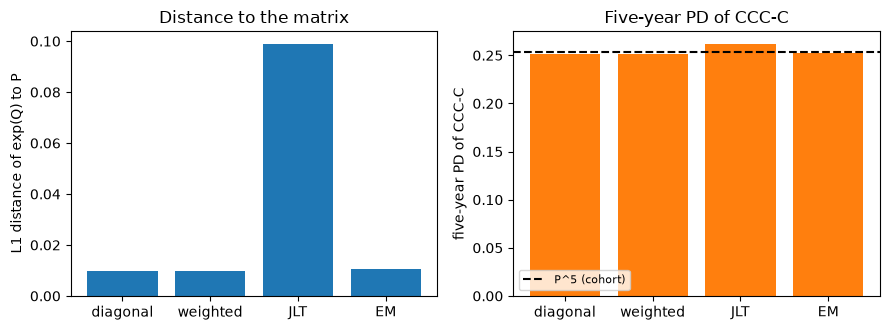

In [9]:
# Draw the L1 distance of each candidate generator and the five-year PD of CCC-C it implies
names = ["diagonal", "weighted", "jlt", "em"]
labels = ["diagonal", "weighted", "JLT", "EM"]
l1_values = [embedding.l1_distance(P, candidates[n]) for n in names]
pd5_values = [expm(5 * candidates[n])[6, -1] for n in names]
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.4))
left.bar(labels, l1_values, color="tab:blue")
left.set_ylabel("L1 distance of exp(Q) to P")
left.set_title("Distance to the matrix")
right.bar(labels, pd5_values, color="tab:orange")
right.axhline(p5[6, -1], color="black", linestyle="--", label="P^5 (cohort)")
right.set_ylabel("five-year PD of CCC-C")
right.set_title("Five-year PD of CCC-C")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **No exact generator.** The pooled S&P matrix has S = 0.121 (below 1, and every diagonal entry is above 1/2, so a generator, if there were one, would be unique) and its determinant 0.3364 sits between 0 and the product of the diagonal, 0.3471, so conditions (a) and (b) of Theorem 3 do not exclude it. Condition (c) does, in six pairs, and Lemma 1 finds four monotonicity violations. The diagnostics equal the committed block.
- **The log series is exact and not a generator.** It sums 28 terms, sits 1.7e-15 from SciPy's `logm`, gives back the matrix to 1.4e-15 and has nine negative off-diagonal entries, the most negative CCC-C to BB (-0.0036).
- **Repairs and EM, by distance.** The L1 distance of exp(Q) to the matrix is 0.00998 for the diagonal repair, 0.00980 for the weighted one, 0.01063 for the EM generator and 0.0989 for JLT, which is ten times further because it assumes at most one transition a year. All four equal the committed values.
- **The choice shows at five years.** At one year the generators give B and CCC-C the matrix's PD within 0.05 points for diagonal, weighted and EM, and 1.5% against 1.17% for B under JLT. At five years CCC-C is 25.30% by the matrix to the fifth power, 25.15% diagonal, 25.09% weighted, 25.27% EM and 26.18% JLT; AAA goes from exactly 0 at one year (the matrix) to 0.007% by every generator, and to 0.102% (P^5), 0.127%, 0.126%, 0.123% and 0.138% at five years.
- **Against the print.** Eight of the nine L1 distances Israel et al. print are reproduced to the printed digits. The ninth, JLT on S&P 1981 to 1991, prints 0.1169 where equation (3) on the printed matrix gives 0.1165; starting from the paper's printed four-digit generator the same distance is 0.1169, so the print follows the generator, not the matrix.

What this notebook does not show: whether the Markov model fits the data at all (notebook 04), or a generator with macroeconomic conditioning (notebook 08).

## Summary

- A one-year matrix has an exact generator only if the log series converges, no condition of Theorem 3 excludes it and the result has non-negative off-diagonal entries; an empirical matrix rarely does.
- The diagonal and weighted repairs and the EM generator stay near the matrix; JLT is ten times further here.
- The generator is part of the PD at a longer horizon: the five-year PD of CCC-C moves by about a point across the candidates, and a grade with a zero one-year PD gets a positive one.
- A recomputation that does not match a print is reported with its explanation, never adjusted.

**What to try next.** Compute the log series of the 2000 cohort matrix of notebook 01 and see how many negative entries a single year gives; then read notebook 04.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Israel, R. B., Rosenthal, J. S. and Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, with applications to credit ratings, Mathematical Finance 11(2), 245-265, Theorems 1 to 3, Lemma 1 and equations (2), (2') and (3). https://doi.org/10.1111/1467-9965.00114
- Jarrow, R. A., Lando, D. and Turnbull, S. M. (1997), A Markov model for the term structure of credit risk spreads, Review of Financial Studies 10(2), as cited by the engine for equation (3) and Lemma 1.
- Bladt, M. and Sorensen, M. (2005), Journal of the Royal Statistical Society B 67(3), and Smith, A. and dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627, for the EM generator.